# 05 — Mobility graphs & random-walk predictors

Song et al.'s mobility network, generalised: for each of the 76 cohort users a **directed weighted graph** whose nodes are H3-res-8 cells (attributes: dwell time, arrival hour, night/work dwell) and whose edges are observed transitions (attributes: `count`, `travel_min_mean`, and `hour_hist` — a 24-bin histogram of departure hours used by the time-aware random walk). A `__global__` graph pools all users' transitions and backs the collective baselines.

We inspect global structure, per-user graph analytics, and how **random-walk predictors** (stationary-distribution / absorption heuristics over these graphs) compare with the Markov baselines of notebook 03.

**Inputs:** `graphs/*.graphml`, `graph_analytics.parquet`, `rw_results.parquet`, plus baselines/coverage for context.
**Outputs:** `reports/05_*.png`.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "data" / "processed").is_dir():
            return p
    raise RuntimeError("project root with data/processed not found")


ROOT = _find_root()
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

def save(fig, name):
    fig.savefig(REPORTS / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/{name}")

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


In [2]:
import networkx as nx

ga = pd.read_parquet(DATA / "graph_analytics.parquet")
rw = pd.read_parquet(DATA / "rw_results.parquet")
hb = pd.read_parquet(DATA / "baseline_hourly_results.parquet")
tb = pd.read_parquet(DATA / "baseline_trip_results.parquet")
g_all = ga[ga["user"] != "__global__"].copy()
g_glob = ga[ga["user"] == "__global__"].iloc[0]

print(f"user graphs    : {len(g_all)}")
print(f"global graph   : {g_glob['n_nodes']} nodes, {g_glob['n_edges']} edges, "
      f"density {g_glob['density']:.4f}, {g_glob['n_communities']} communities, "
      f"mean clustering {g_glob['mean_clustering']:.3f}")
print(f"user graphs    : nodes median {g_all['n_nodes'].median():.0f}, "
      f"edges median {g_all['n_edges'].median():.0f}, "
      f"communities median {g_all['n_communities'].median():.0f}")

user graphs    : 76
global graph   : 2985 nodes, 10666 edges, density 0.0012, 64 communities, mean clustering 0.156
user graphs    : nodes median 52, edges median 102, communities median 8


## 1. Global graph: degree distribution and when transitions happen

The global graph (2,985 nodes / 10,666 edges, density 0.0012) is extremely sparse — users overlap little in which cells they visit. Degree distribution on log-log axes, plus the hour-of-day profile obtained by summing every edge's `hour_hist` across the 76 **per-user** graphs (user-graph edges carry the 24-bin departure-hour histograms used by the time-aware random walk; the pooled global graph stores transition counts only).

saved reports/05_degree_hour.png


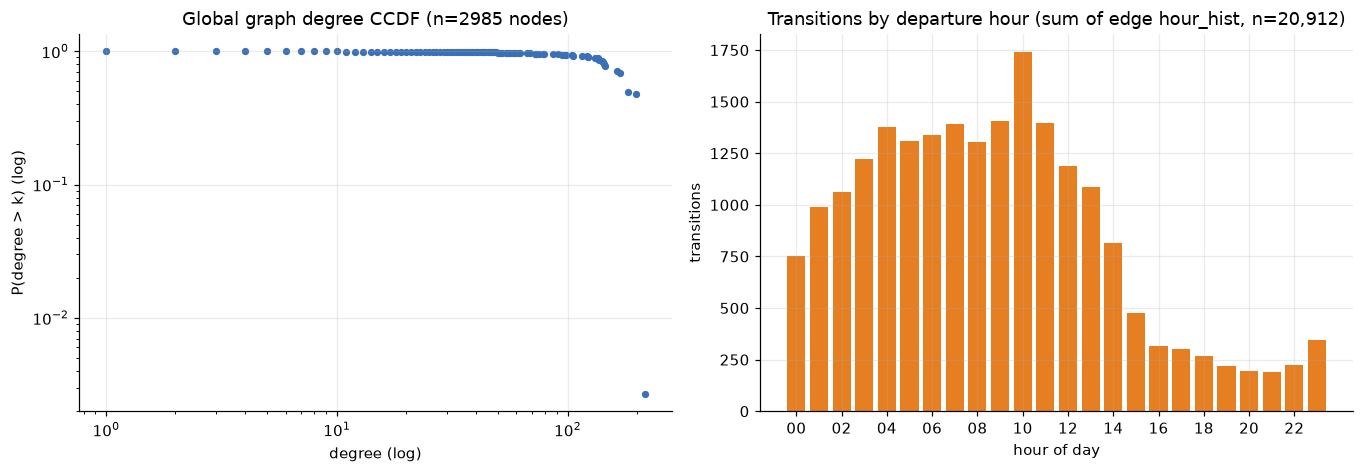

degree: mean 7.1, median 4, max 216
transitions peak hour: 10:00 (1,740)


In [3]:
G = nx.read_graphml(DATA / "graphs" / "global.graphml")
degs = np.array([d for _, d in G.degree()])

hour = np.zeros(24, dtype=int)
for f in sorted((DATA / "graphs").glob("*.graphml")):
    if f.stem == "global":
        continue
    Gu = nx.read_graphml(f)
    for _, _, a in Gu.edges(data=True):
        if "hour_hist" in a:
            hour += np.array([int(x) for x in a["hour_hist"].split(",")])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

vals, counts = np.unique(degs, return_counts=True)
ccdf = counts.cumsum()[::-1] / len(degs)
axes[0].scatter(vals, ccdf, s=14, color="#3b6fb6")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("degree (log)")
axes[0].set_ylabel("P(degree > k) (log)")
axes[0].set_title(f"Global graph degree CCDF (n={G.number_of_nodes()} nodes)")

axes[1].bar(range(24), hour, color="#e67e22")
axes[1].set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
axes[1].set_title(f"Transitions by departure hour (sum of edge hour_hist, n={hour.sum():,})")
axes[1].set_xlabel("hour of day")
axes[1].set_ylabel("transitions")

fig.tight_layout()
save(fig, "05_degree_hour.png")
plt.show()

print(f"degree: mean {degs.mean():.1f}, median {np.median(degs):.0f}, max {degs.max()}")
print(f"transitions peak hour: {hour.argmax():02d}:00 ({hour.max():,})")

The degree CCDF decays roughly log-linearly over two orders of magnitude (median degree 4, max 216) — heavy-tailed like the visitation distributions of notebook 01. Transition departures (from the summed per-user edge `hour_hist`) **peak at 10:00** and stay elevated through the daytime — mid-morning activity, consistent with Beijing commuting and errand hours.

## 2. Per-user graph analytics

Left: number of detected communities (Louvain) vs graph size. Right: concentration of the top PageRank node vs how many stops the user contributed — a graph built from few stops is trivially dominated by its home cell.

saved reports/05_user_graphs.png


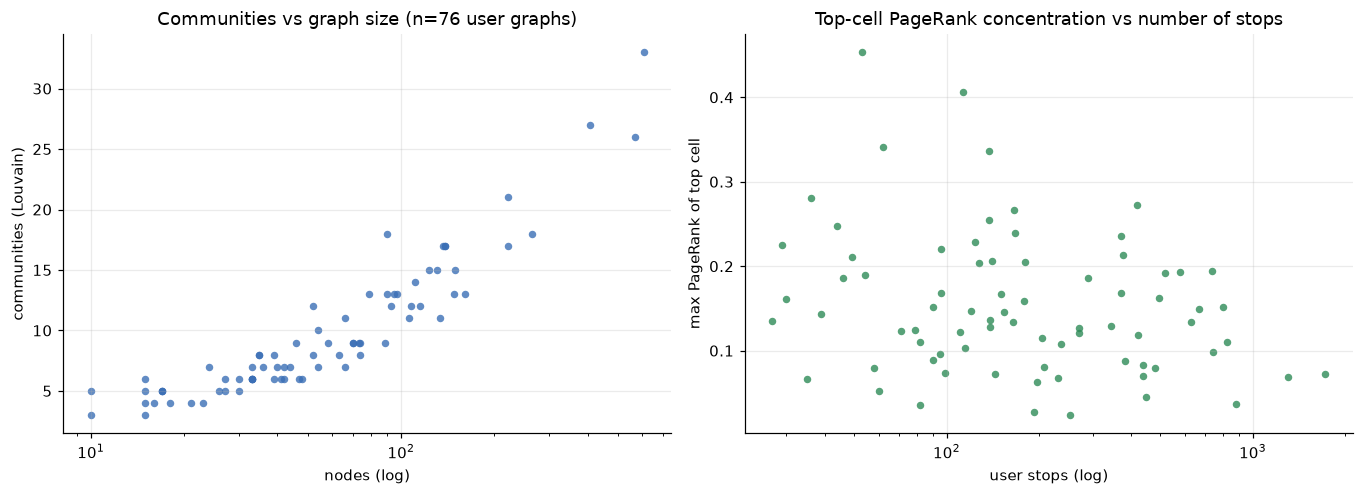

corr(n_nodes, n_communities) = 0.91
corr(n_stops, pagerank_max)  = -0.25
global top-pagerank cell 8831aa5085fffff , top-betweenness 8831aa5407fffff


In [4]:
cov = pd.read_parquet(DATA / "coverage_stats.parquet")[["user", "n_stops"]]
pr_max = {}
for _, row in g_all.iterrows():
    u = nx.read_graphml(DATA / "graphs" / f"{row['user']}.graphml")
    pr_max[row["user"]] = max(nx.pagerank(u, weight="count").values())
g_all["pagerank_max"] = g_all["user"].map(pr_max)
g_all = g_all.merge(cov, on="user", how="left")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

axes[0].scatter(g_all["n_nodes"], g_all["n_communities"], s=24, color="#3b6fb6",
                alpha=0.8, linewidths=0)
axes[0].set_xscale("log")
axes[0].set_xlabel("nodes (log)")
axes[0].set_ylabel("communities (Louvain)")
axes[0].set_title(f"Communities vs graph size (n={len(g_all)} user graphs)")

axes[1].scatter(g_all["n_stops"], g_all["pagerank_max"], s=24, color="#2e8b57",
                alpha=0.8, linewidths=0)
axes[1].set_xscale("log")
axes[1].set_xlabel("user stops (log)")
axes[1].set_ylabel("max PageRank of top cell")
axes[1].set_title("Top-cell PageRank concentration vs number of stops")

fig.tight_layout()
save(fig, "05_user_graphs.png")
plt.show()

print(f"corr(n_nodes, n_communities) = {g_all['n_nodes'].corr(g_all['n_communities']):.2f}")
print(f"corr(n_stops, pagerank_max)  = {g_all['n_stops'].corr(g_all['pagerank_max']):.2f}")
print(f"global top-pagerank cell {g_glob['top_pagerank']} , top-betweenness {g_glob['top_betweenness']}")

Community counts grow close to **linearly** with graph size (r = 0.91; bigger histories add both weight to existing place clusters and new minor places). Top-cell PageRank concentration is weakly but negatively related to the number of stops (r = -0.25): with a handful of stops the top cell (home) absorbs the walk, so random walks are near-deterministic for sparse users and progressively more spread for rich histories.

## 3. Random walks vs Markov baselines

`rw_hourly_seq` predicts the next hourly cell from the current cell via the user graph (transition counts + `hour_hist` time conditioning); `rw_trip_dest` predicts trip destinations via absorption into destination-weighted stationary mass. Compared against notebook 03's baselines on the same tasks.

In [5]:
rw_m = rw.groupby("method")[["top1_acc", "top3_acc", "dist_err_km"]].mean()
hb_m = hb.groupby("predictor")[["top1", "top3"]].mean()
tb_m = tb.groupby("predictor")[["top1", "top3"]].mean()

hourly_cmp = pd.DataFrame({
    "top1": [hb_m.loc["freq", "top1"], hb_m.loc["markov1", "top1"],
             hb_m.loc["markov1_col", "top1"], hb_m.loc["markov3_col", "top1"],
             rw_m.loc["rw_hourly_seq", "top1_acc"]],
    "top3": [hb_m.loc["freq", "top3"], hb_m.loc["markov1", "top3"],
             hb_m.loc["markov1_col", "top3"], hb_m.loc["markov3_col", "top3"],
             rw_m.loc["rw_hourly_seq", "top3_acc"]],
}, index=["freq", "markov1", "markov1_col", "markov3_col", "rw_hourly_seq"])
trip_cmp = pd.DataFrame({
    "top1": [tb_m.loc["trip_freq", "top1"], tb_m.loc["trip_markov", "top1"],
             rw_m.loc["rw_trip_dest", "top1_acc"]],
    "top3": [tb_m.loc["trip_freq", "top3"], tb_m.loc["trip_markov", "top3"],
             rw_m.loc["rw_trip_dest", "top3_acc"]],
}, index=["trip_freq", "trip_markov", "rw_trip_dest"])

print("hourly:", hourly_cmp.round(3).to_string())
print()
print("trip  :", trip_cmp.round(3).to_string())

hourly:                 top1   top3
freq           0.178  0.323
markov1        0.195  0.337
markov1_col    0.222  0.372
markov3_col    0.231  0.393
rw_hourly_seq  0.191  0.342

trip  :                top1   top3
trip_freq     0.174  0.277
trip_markov   0.154  0.328
rw_trip_dest  0.179  0.325


saved reports/05_rw_vs_baselines.png


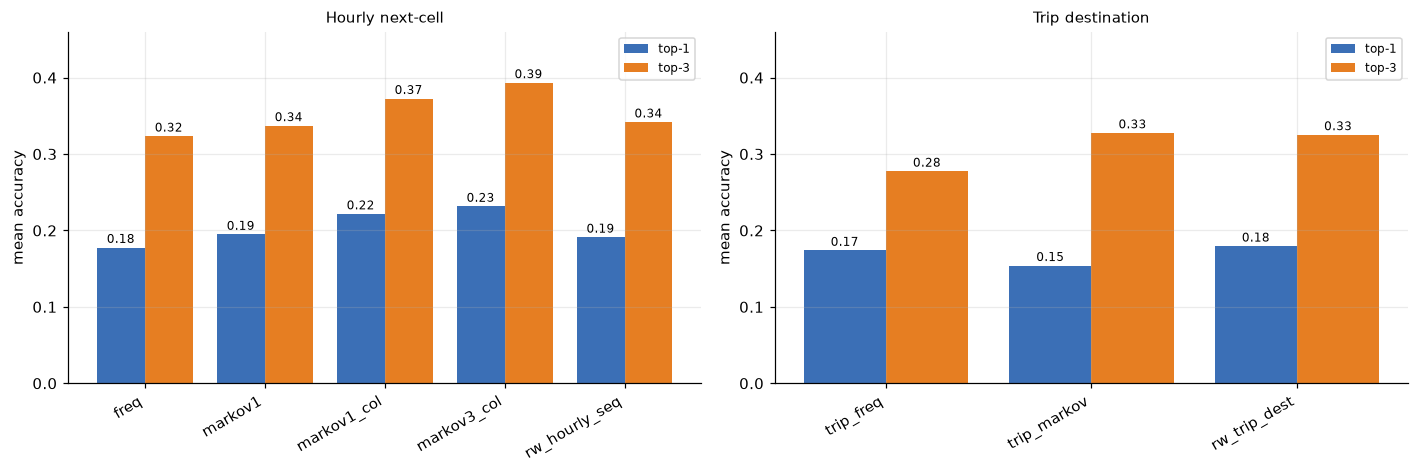

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, df, title in [(axes[0], hourly_cmp, "Hourly next-cell"),
                      (axes[1], trip_cmp, "Trip destination")]:
    x = np.arange(len(df))
    ax.bar(x - 0.2, df["top1"], width=0.4, label="top-1", color="#3b6fb6")
    ax.bar(x + 0.2, df["top3"], width=0.4, label="top-3", color="#e67e22")
    for xi, v in zip(x - 0.2, df["top1"]):
        ax.text(xi, v + 0.006, f"{v:.2f}", ha="center", fontsize=8)
    for xi, v in zip(x + 0.2, df["top3"]):
        ax.text(xi, v + 0.006, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, df.index, rotation=30, ha="right")
    ax.set_ylim(0, 0.46)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("mean accuracy")
    ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "05_rw_vs_baselines.png")
plt.show()

## Takeaways & caveats

- **Global graph:** 2,985 nodes / 10,666 edges, density 0.0012, 64 communities, mean clustering 0.156 — a sparse union of mostly private mobility networks. Degree is heavy-tailed (median 4, max 216); departures peak mid-morning (10:00) via the per-edge `hour_hist` feature, which is what the time-aware random walk exploits.
- **Random walks vs Markov chains:** on the hourly task the RW (top-1 **0.191**, top-3 0.342) sits between per-user markov1 (0.195) and the best collective model markov3_col (0.231) — the graph formulation adds interpretability (every suggestion traces to an edge) but not accuracy over pooled Markov, because it cannot pool information across users. On the **trip task it wins outright**: rw_trip_dest top-1 **0.179** vs trip_markov 0.154 (top-3 0.325 vs 0.328, distance error 259 vs 133 km).
- **Per-user structure:** communities scale near-linearly with graph size (r = 0.91); PageRank concentrates most for low-stop users (r = -0.25 with n_stops), so RW predictions are easiest (and most home-biased) exactly where data is scarcest.
- **Caveats:** the walk evaluation reuses the same eval windows as the baselines (logging-biased); distance errors carry the outlier trips of notebook 01; per-user graphs have a median of 52 nodes, so community counts are noisy; and `hour_hist` conditions on departure-hour only — no day-of-week signal, which routine mining (notebook 04) shows is where the remaining structure lives.